<a href="https://colab.research.google.com/github/lulusbersamasama-TE/solar-ai-mppt-optimization/blob/main/notebooks/01_irradiance_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Irradiance Forecasting (SRRL)

5-minute future GHI prediction from **only past/current** meteorological observations. Compare persistence (baseline), linear regression and random forest. Chronological 70/15/15 with temporal purge. Requires `data/srrl_weather_compact.csv.gz` and `data/pv_database_summary_extract.csv` for root detection.

In [1]:
from google.colab import drive
from pathlib import Path
import os

# Menghubungkan Google Drive
drive.mount('/content/drive')

# Folder proyek di Google Drive
project = Path(
    '/content/drive/MyDrive/solar_ai_mppt_project'
)

# Memastikan folder tersedia
(project / 'data').mkdir(parents=True, exist_ok=True)
(project / 'outputs').mkdir(parents=True, exist_ok=True)

# Menyesuaikan lokasi dengan notebook
link = Path('/content/solar_ai_mppt_project')

if not link.exists():
    os.symlink(
        project,
        link,
        target_is_directory=True
    )

# Memvalidasi file dataset
required = [
    'srrl_weather_compact.csv.gz',
    'pv_database_summary_extract.csv',
    'pv_iv_curves_0p1V.npz'
]

for filename in required:
    path = project / 'data' / filename
    print(filename, 'OK' if path.exists() else 'MISSING')


Mounted at /content/drive
srrl_weather_compact.csv.gz OK
pv_database_summary_extract.csv OK
pv_iv_curves_0p1V.npz OK


In [2]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
ROOT = next((p for p in [Path.cwd(),Path.cwd().parent,Path('/content/solar_ai_mppt_project')]
             if (p/'data'/'pv_database_summary_extract.csv').exists()),None)
if ROOT is None:
    raise FileNotFoundError('Place the three derived dataset files in data/ (see data/README.md).')
DATA=ROOT/'data'; OUT=ROOT/'outputs'; OUT.mkdir(exist_ok=True)
FAST=os.getenv('SOLAR_FAST','0')=='1'; SEED=42
print('Root:',ROOT,'Fast mode:',FAST)

Root: /content/solar_ai_mppt_project Fast mode: False


## A. Data integrity

The timestamps are observation timestamps, not chronological continuity guarantees. Missing and invalid data must not be silently forward-filled across nighttime gaps.

In [3]:
types={x:'float32' for x in ['ghi','dhi','dni','temperature_c','rh_pct','zenith_deg','ghi_extraterrestrial']}
w=pd.read_csv(DATA/'srrl_weather_compact.csv.gz',parse_dates=['timestamp'],dtype=types)
w=w.sort_values('timestamp').reset_index(drop=True)
print('Raw records',len(w),'duplicates',w.timestamp.duplicated().sum(),'GHI negative',(w.ghi<0).sum())
print(w.isna().sum().to_string())
assert w.timestamp.notna().all() and not w.timestamp.duplicated().any()
assert w.timestamp.is_monotonic_increasing

Raw records 1730394 duplicates 0 GHI negative 1444
ghi                     0
ghi_extraterrestrial    0
dni                     0
dhi                     0
zenith_deg              0
temperature_c           0
rh_pct                  0
timestamp               0


## B. Causal preprocessing / feature engineering

Build lag features only within uninterrupted one-minute segments; the target is exactly t+5 min, with no nighttime or missing-minute jumps.

In [4]:
w=w.loc[w.ghi.between(0,1500)&w.zenith_deg.between(0,90)].copy()
for col,lo,hi in [('temperature_c',-45,70),('rh_pct',0,100),('dhi',-5,1500),('dni',-5,1500)]:
    w.loc[~w[col].between(lo,hi),col]=np.nan
w['segment']=w.timestamp.diff().ne(pd.Timedelta(minutes=1)).cumsum()
g=w.groupby('segment',sort=False)
for lag in [1,5,15]: w[f'ghi_lag{lag}']=g.ghi.shift(lag)
for width in [5,15]:
    w[f'ghi_roll{width}']=g.ghi.transform(lambda z:z.rolling(width,min_periods=width).mean())
w['ghi_delta1']=w.ghi-w.ghi_lag1
w['ghi_tplus5']=g.ghi.shift(-5)
w['target_timestamp']=g.timestamp.shift(-5)
FEATURES=['ghi','ghi_lag1','ghi_lag5','ghi_lag15','ghi_roll5','ghi_roll15','ghi_delta1',
          'dhi','dni','temperature_c','rh_pct','zenith_deg','ghi_extraterrestrial']
data=w.loc[(w.ghi>=50)&(w.target_timestamp-w.timestamp==pd.Timedelta(minutes=5)),
           FEATURES+['timestamp','target_timestamp','ghi_tplus5']].dropna().reset_index(drop=True)
assert not data.empty
print('Usable windows:',len(data))

Usable windows: 1501601


## C. Chronological split with 15-minute purge

In [5]:
t70,t85=data.target_timestamp.quantile([.70,.85]).tolist()
purge=pd.Timedelta(minutes=15)
train=data.loc[data.target_timestamp<=t70].copy()
valid=data.loc[(data.target_timestamp>t70+purge)&(data.target_timestamp<=t85)].copy()
test=data.loc[data.target_timestamp>t85+purge].copy()
assert len(train) and len(valid) and len(test)
assert train.target_timestamp.max()<valid.timestamp.min()
assert valid.target_timestamp.max()<test.timestamp.min()
for name,d in [('train',train),('validation',valid),('test',test)]:
    print(name,len(d),d.target_timestamp.min(),d.target_timestamp.max())

train 1051121 2020-01-01 08:46:00 2024-07-14 05:29:00
validation 225225 2024-07-14 05:45:00 2025-07-09 07:54:00
test 225225 2025-07-09 08:10:00 2026-06-30 18:37:00


## D. Fit baseline models and evaluate

RF uses a random sample from **training only** to control Colab runtime; validation/test remain chronological and complete.

In [6]:
linear=LinearRegression().fit(train[FEATURES],train.ghi_tplus5)
rf_train=train.sample(n=min(len(train),25000 if FAST else 120000),random_state=SEED)
rf=RandomForestRegressor(n_estimators=35 if FAST else 100,max_depth=17,min_samples_leaf=3,
                         n_jobs=-1,random_state=SEED)
rf.fit(rf_train[FEATURES],rf_train.ghi_tplus5)
def predict(d):
    return {'Persistence':d.ghi.to_numpy(),
            'Linear Regression':np.clip(linear.predict(d[FEATURES]),0,None),
            'Random Forest':np.clip(rf.predict(d[FEATURES]),0,None)}
rows=[]
for subset,d in [('validation',valid),('test',test)]:
    for name,yhat in predict(d).items():
        rows.append({'subset':subset,'model':name,'MAE_Wm2':mean_absolute_error(d.ghi_tplus5,yhat),
                     'RMSE_Wm2':np.sqrt(mean_squared_error(d.ghi_tplus5,yhat)),
                     'R2':r2_score(d.ghi_tplus5,yhat)})
metrics=pd.DataFrame(rows)
print(metrics.round(3).to_string(index=False))
metrics.to_csv(OUT/'irradiance_metrics.csv',index=False)

    subset             model  MAE_Wm2  RMSE_Wm2    R2
validation       Persistence   50.840   114.237 0.836
validation Linear Regression   56.672   106.346 0.858
validation     Random Forest   47.265   100.554 0.873
      test       Persistence   53.062   116.346 0.829
      test Linear Regression   58.500   108.103 0.852
      test     Random Forest   49.824   102.149 0.868


## E. Export held-out forecasts, models and plot

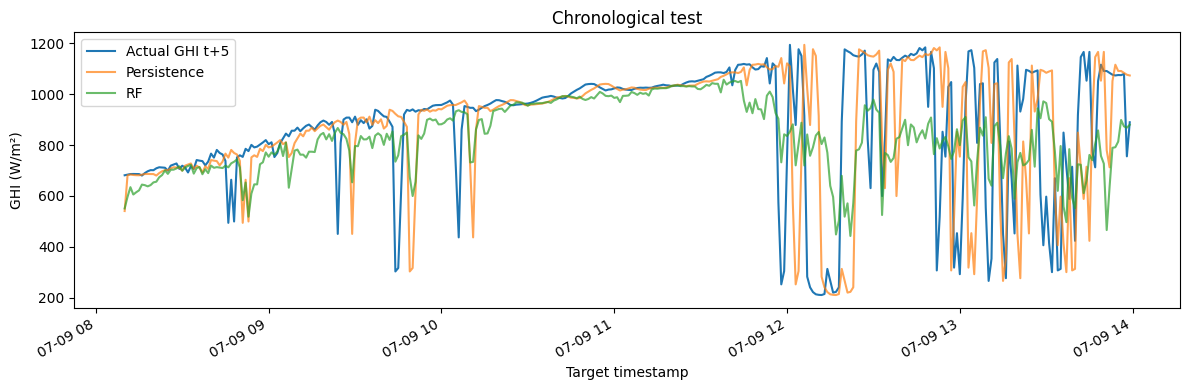

Saved 225225 test forecasts


In [7]:
pred=predict(test)
export=pd.DataFrame({'timestamp':test.timestamp.to_numpy(),
    'target_timestamp':test.target_timestamp.to_numpy(),
    'ghi_now':test.ghi.to_numpy(),'ghi_true_5min':test.ghi_tplus5.to_numpy(),
    'ghi_pred_persistence':pred['Persistence'],'ghi_pred_linear':pred['Linear Regression'],
    'ghi_pred_rf':pred['Random Forest']})
export.to_csv(OUT/'irradiance_test_forecasts.csv.gz',index=False,compression='gzip')
joblib.dump({'linear':linear,'random_forest':rf,'feature_columns':FEATURES,'horizon_minutes':5},
            OUT/'irradiance_models.joblib',compress=3)
view=export.iloc[:min(350,len(export))]
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(view.target_timestamp,view.ghi_true_5min,label='Actual GHI t+5')
ax.plot(view.target_timestamp,view.ghi_pred_persistence,label='Persistence',alpha=.7)
ax.plot(view.target_timestamp,view.ghi_pred_rf,label='RF',alpha=.7)
ax.set(xlabel='Target timestamp',ylabel='GHI (W/m²)',title='Chronological test')
ax.legend();fig.autofmt_xdate();plt.tight_layout()
fig.savefig(OUT/'forecast_test_timeseries.png',dpi=150);plt.show()
print('Saved',len(export),'test forecasts')

## Verification

Check temporal leakage, compare against persistence on test, report MAE/RMSE/R². Forecast accuracy alone does not establish an MPPT energy gain.